In [143]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Perceptron
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import confusion_matrix, recall_score, precision_score, accuracy_score
from sklearn.neural_network import MLPClassifier

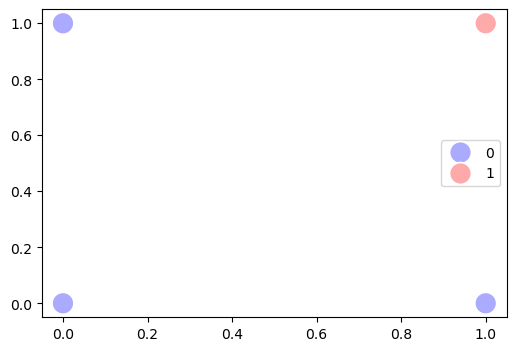

In [32]:
# Creating and gate
X = np.array([0, 0, 0, 1, 1, 0, 1, 1]).reshape(4, 2)
y = np.array([0, 0, 0, 1])

plt.figure(figsize=(6, 4))
sns.scatterplot(x=X[:,0], y=X[:, 1], hue=y.astype(str), s=250, marker='o', palette='bwr')
plt.show()


In [33]:
model = Perceptron(max_iter=50, eta0=0.5)
model.fit(X, y)

,penalty,None
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,50
,tol,0.001
,shuffle,True
,verbose,0
,eta0,0.5
,n_jobs,None
,random_state,0


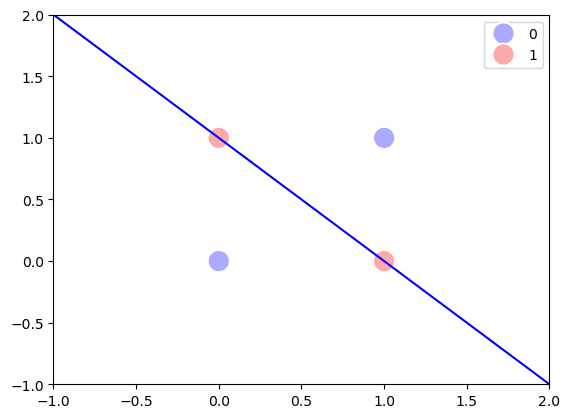

In [109]:
plt.figure()
sns.scatterplot(x=X[:,0], y=X[:, 1], hue=y.astype(str), s=250, marker='o', palette='bwr')
display = DecisionBoundaryDisplay.from_estimator(
    model, 
    X,
    response_method='decision_function', plot_method='contour',
    ax=plt.gca(),
    alpha=1,
    cmap='bwr',
    levels=[0]
)
plt.show()

In [125]:
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([0, 1, 1, 0])
def step(z):
    return 1 if z >= 0 else 0

w = np.random.randn(2)
b = 0.0
lr = 0.1

for epoch in range(1000):
    errors = 0
    for xi, target in zip(X, y):
        y_pred = step(w @ xi + b)
        err = target - y_pred
        w += lr * err * xi
        b += lr * err
        errors += abs(err)
    if errors == 0:
        print("Converged at epoch", epoch)
        break
else:
    print("Did not converge (expected for XOR)")

Did not converge (expected for XOR)


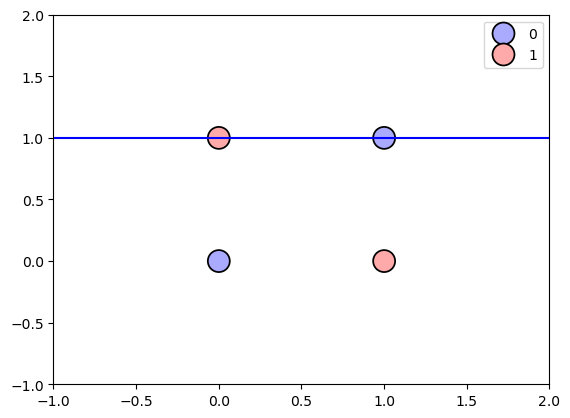

In [138]:
model = Perceptron(shuffle=True, random_state=26)
model.fit(X, y)
fig, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator(
    model, X,
    response_method='decision_function',
    plot_method='contour',
    cmap='bwr',
    ax=ax,
    levels=[0]
)
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y, s=250, palette='bwr', ax=ax, edgecolor='k')
plt.show()

In [139]:
confusion_matrix(y, model.predict(X))

array([[2, 0],
       [2, 0]])

In [142]:
# This problem  can  be solved by the multilayer perceptron

In [174]:
model = MLPClassifier(
    solver='sgd', 
    hidden_layer_sizes=(4, ),
    activation='tanh',
    random_state=26,
    max_iter=1000,
    verbose=True,
    tol=1e-5, 
    momentum=0.7,
    learning_rate_init=0.2
)
model.fit(X, y)

Iteration 1, loss = 0.72385456
Iteration 2, loss = 0.71058316
Iteration 3, loss = 0.69931485
Iteration 4, loss = 0.69154477
Iteration 5, loss = 0.68661177
Iteration 6, loss = 0.68320317
Iteration 7, loss = 0.68028110
Iteration 8, loss = 0.67733152
Iteration 9, loss = 0.67423256
Iteration 10, loss = 0.67103851
Iteration 11, loss = 0.66782805
Iteration 12, loss = 0.66464155
Iteration 13, loss = 0.66147712
Iteration 14, loss = 0.65830884
Iteration 15, loss = 0.65510461
Iteration 16, loss = 0.65183597
Iteration 17, loss = 0.64848054
Iteration 18, loss = 0.64502069
Iteration 19, loss = 0.64144125
Iteration 20, loss = 0.63772783
Iteration 21, loss = 0.63386601
Iteration 22, loss = 0.62984113
Iteration 23, loss = 0.62563835
Iteration 24, loss = 0.62124274
Iteration 25, loss = 0.61663930
Iteration 26, loss = 0.61181296
Iteration 27, loss = 0.60674852
Iteration 28, loss = 0.60143066
Iteration 29, loss = 0.59584402
Iteration 30, loss = 0.58997333
Iteration 31, loss = 0.58380355
Iteration 32, los

,hidden_layer_sizes,"(4,)"
,activation,'tanh'
,solver,'sgd'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.2
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,26


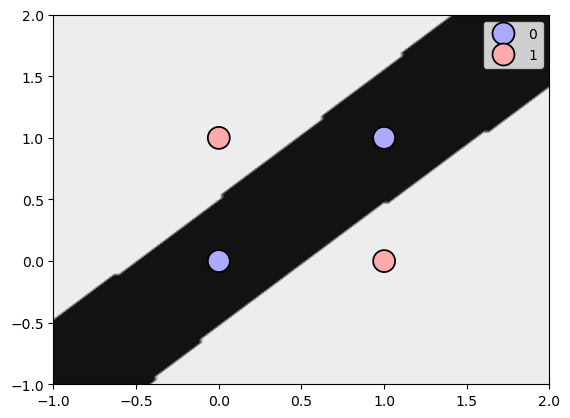

In [175]:

fig, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator(
    model, X,
    response_method='predict',
    plot_method='contourf',
    cmap='grey',
    ax=ax,
    # levels=[0]
)
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y, s=250, palette='bwr', ax=ax, edgecolor='k')
plt.show()

In [168]:
confusion_matrix(y, model.predict(X))

array([[2, 0],
       [0, 2]])